# 04 · Random Forest and XGBoost

**Goal of this notebook:** train two tree-based models, Random Forest and XGBoost, on exactly the
same features and chronological splits as the Logistic Regression baseline (notebook 03), and
see whether non-linear models predict Serie A results better.

| Step | Seasons |
|---|---|
| Train | 1993-94 to 2024-25 |
| Validate: choose feature set and hyperparameters by log loss | 2025-26 |
| Final training | 1993-94 to 2025-26 |
| Test | 2026-27, completed matches only |

The same run is available from the command line:

```powershell
python -m src.train                                       # all three models
python -m src.train --models random_forest xgboost        # selected models
```

Model definitions and tuning grids live in `src/models.py`; the shared training workflow is in
`src/train.py`. A more detailed comparison of all models follows in the next commit.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.inspection import permutation_importance

from src.config import FIGURES_DIR
from src.evaluate import OUTCOME_NAMES, OUTCOMES
from src.feature_engineering import load_features
from src.models import MODEL_SPECS
from src.train import (
    BASELINE_LABEL, chronological_split, comparison_table, feature_matrix, run_experiment,
    save_artifacts, save_comparison, target, TRAIN_LAST_SEASON, VALIDATION_SEASON,
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

features = load_features()
experiments = {}
for name in MODEL_SPECS:  # logistic_regression, random_forest, xgboost
    experiments[name] = run_experiment(features, model_name=name)
    save_artifacts(experiments[name])
comparison_path = save_comparison(list(experiments.values()))

lr, rf, xgb = experiments["logistic_regression"], experiments["random_forest"], experiments["xgboost"]
for e in experiments.values():
    params = ", ".join(f"{k} = {v}" for k, v in e.params.items())
    print(f"{e.label:>20}: feature set '{e.feature_set}', {params}")

 Logistic Regression: feature set 'compact', C = 0.001
       Random Forest: feature set 'compact', max_depth = 12, min_samples_leaf = 10
             XGBoost: feature set 'compact', max_depth = 2, n_estimators = 250


In [2]:
# --- Chart style (same as notebooks 01-03) -------------------------------------
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
BLUE, AQUA, ORANGE, GRAY = "#2a78d6", "#1baf7a", "#eb6834", "#a3a29b"
OUTCOME_COLORS = {"H": BLUE, "D": AQUA, "A": ORANGE}
# One fixed colour per model, used in every chart (categorical slots 1-3)
MODEL_COLORS = {"Logistic Regression": BLUE, "Random Forest": ORANGE, "XGBoost": AQUA, BASELINE_LABEL: GRAY}
SEQ = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#cde2fb", "#86b6ef", "#2a78d6", "#104281"])


def style_axes(ax, grid="y"):
    ax.set_facecolor(SURFACE)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE)
    ax.tick_params(colors=MUTED, labelsize=8, length=0)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)


def set_title(ax, title, subtitle=None, size=12):
    ax.set_title(title, loc="left", fontsize=size, color=INK, pad=26 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.015, subtitle, transform=ax.transAxes, fontsize=9, color=INK_2, va="bottom")


def save_figure(fig, name):
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / name, dpi=150, facecolor=SURFACE, bbox_inches="tight")

## 1. How the tree models work here

| | Logistic Regression (notebook 03) | Random Forest | XGBoost |
|---|---|---|---|
| Idea | One weighted sum of the features per outcome | Average of many decision trees, each trained on a random sample of matches and features | Trees added one after another, each correcting the errors of the previous ones |
| Can model | Straight-line (linear) effects | Non-linear effects and interactions | Non-linear effects and interactions |
| Missing history | Median + missing indicators | Median + missing indicators | Handled natively: each split learns where missing values go |
| Scaling | Standardised | Not needed | Not needed |
| Main overfitting control | L2 penalty `C` | Tree depth `max_depth`, leaf size `min_samples_leaf` | Tree depth `max_depth`, number of trees, small learning rate (0.03) |

As before, each model is a scikit-learn `Pipeline` fitted on training rows only, and both
feature sets (`all` = 50 features, `compact` = 22) are tried for every hyperparameter
combination.

In [3]:
rf.model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('impute', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['A','D','H']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['home_history_matches','home_form10_ppg','home_form10_gd',..., 'away_prev_season_ppg','away_prev_season_gd','away_promoted']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",True
,"missing_values missing_values: int, float, st

In [4]:
xgb.model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U1](3,)","['A','D','H']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,n_estimators,250
,max_depth,2
,learning_rate,0.03
,min_child_weight,10.0


## 2. Tuning on the validation season

Each cell is the 2025-26 log loss of one candidate (lower is better), for the selected feature set.

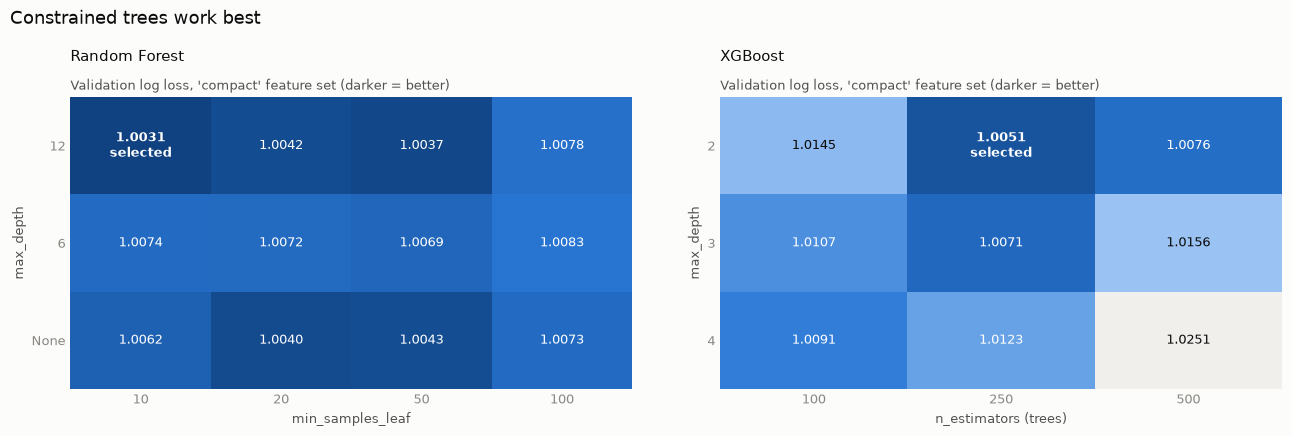

In [5]:
def tuning_grid(experiment, rows, cols):
    table = experiment.tuning[experiment.tuning["feature_set"] == experiment.feature_set].copy()
    table[rows] = table[rows].astype(object).where(table[rows].notna(), "None")
    table[rows] = table[rows].map(lambda v: str(int(v)) if isinstance(v, float) else str(v))
    return table.pivot(index=rows, columns=cols, values="log_loss")


grids = [
    (rf, tuning_grid(rf, "max_depth", "min_samples_leaf"), "max_depth", "min_samples_leaf"),
    (xgb, tuning_grid(xgb, "max_depth", "n_estimators"), "max_depth", "n_estimators (trees)"),
]
low = min(g.min().min() for _, g, _, _ in grids)
high = max(g.max().max() for _, g, _, _ in grids)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), facecolor=SURFACE)
for ax, (experiment, table, ylabel, xlabel) in zip(axes, grids):
    ax.imshow(table.values, cmap=SEQ.reversed(), vmin=low, vmax=high, aspect="auto")  # dark = better
    best = experiment.tuning.iloc[0]
    for i, row in enumerate(table.index):
        for j, col in enumerate(table.columns):
            value = table.iloc[i, j]
            is_best = str(row) == str(best[table.index.name] if pd.notna(best[table.index.name]) else "None").replace(".0", "") and col == best[table.columns.name]
            ax.text(j, i, f"{value:.4f}" + ("\nselected" if is_best else ""), ha="center", va="center",
                    fontsize=9, color="#ffffff" if value < (low + high) / 2 else INK,
                    fontweight="bold" if is_best else "normal")
    ax.set_xticks(range(len(table.columns)), table.columns)
    ax.set_yticks(range(len(table.index)), table.index)
    ax.set_xlabel(xlabel, color=INK_2, fontsize=9)
    ax.set_ylabel(ylabel, color=INK_2, fontsize=9)
    ax.tick_params(colors=MUTED, labelsize=9, length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    set_title(ax, experiment.label, f"Validation log loss, '{experiment.feature_set}' feature set (darker = better)", size=11)
fig.suptitle("Constrained trees work best", x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(w_pad=4)
save_figure(fig, "18_tree_model_tuning.png")
plt.show()

In [6]:
best_per_set = (pd.concat([e.tuning.assign(model=e.label) for e in experiments.values()])
                .sort_values("log_loss").groupby(["model", "feature_set"]).head(1)
                .pivot(index="model", columns="feature_set", values="log_loss"))
best_per_set.style.format("{:.4f}").set_caption("Best validation log loss per model and feature set")

feature_set,all,compact
model,,
Logistic Regression,1.0080,1.0022
Random Forest,1.0052,1.0031
XGBoost,1.0061,1.0051


**Interpretation**

- **Random Forest** works best in the middle of its grid, with trees of depth 12 and 10–50
  matches per leaf:
  - Shallow trees (depth 6) and very large leaves (100 matches) **under-fit**: they are too
    coarse to separate strong and weak teams well.
  - Unlimited depth with small leaves (10 matches) **over-fits**: it starts learning noise.
- **XGBoost** prefers very **shallow trees (depth 2)** and a moderate number of them (250 at
  learning rate 0.03):
  - With only 100 trees, boosting stops too early (under-fitting).
  - More trees or deeper trees make validation log loss worse (over-fitting). Depth 4 with 500
    trees is the worst cell.
  - Depth-1 trees, a quick extra check outside the grid, were also slightly worse.
- As with Logistic Regression, the **compact** 22-feature set beats all 50 features for both
  models.
- The whole tuning landscape is very flat: the differences are in the third decimal place, small
  compared with the noise of a single 380-match season.

## 3. Results on validation and test

In [7]:
comparison = comparison_table(list(experiments.values()))
fmt = {"matches": "{:.0f}", "accuracy": "{:.1%}", "macro_f1": "{:.3f}", "log_loss": "{:.3f}",
       "accuracy_H": "{:.1%}", "accuracy_D": "{:.1%}", "accuracy_A": "{:.1%}"}
print(f"Saved to {comparison_path.relative_to(comparison_path.parents[2])}")
comparison.style.format(fmt)

Saved to outputs\models\model_comparison.csv


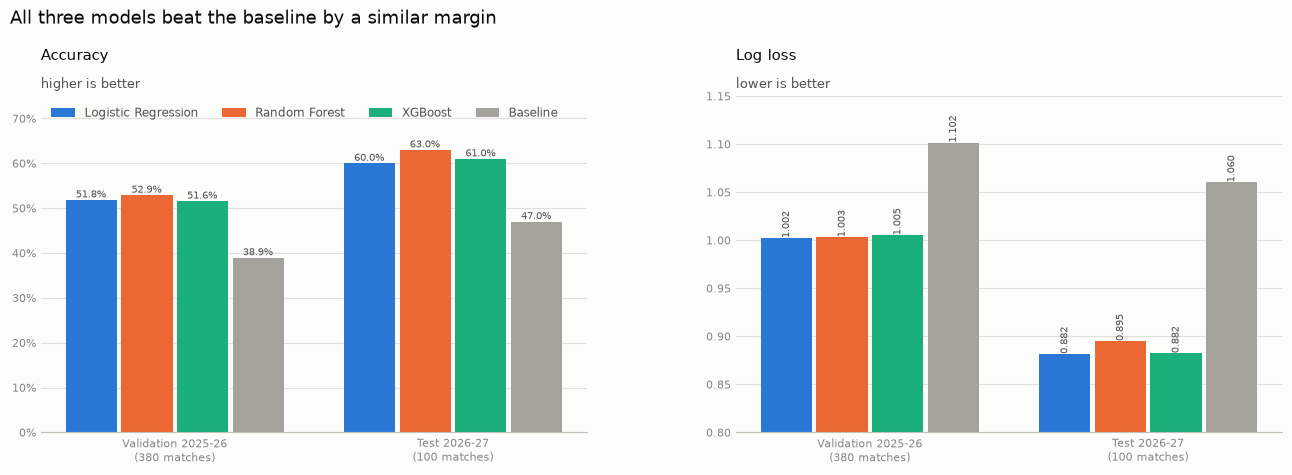

In [8]:
models = ["Logistic Regression", "Random Forest", "XGBoost", BASELINE_LABEL]
panels = [("accuracy", "Accuracy", "higher is better", "{:.1%}"),
          ("log_loss", "Log loss", "lower is better", "{:.3f}")]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), facecolor=SURFACE)
x = np.arange(2)  # validation, test
width = 0.2
for ax, (metric, title, note, label_fmt) in zip(axes, panels):
    for k, model in enumerate(models):
        values = [comparison.loc[(split, model), metric] for split in ("validation", "test")]
        bars = ax.bar(x + (k - 1.5) * width, values, width=width * 0.92, color=MODEL_COLORS[model],
                      label="Baseline" if model == BASELINE_LABEL else model)
        for bar, v in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width() / 2, v, label_fmt.format(v), ha="center", va="bottom",
                    fontsize=7.5, color=INK_2, rotation=90 if metric == "log_loss" else 0)
    ax.set_xticks(x, [f"Validation 2025-26\n({int(comparison.loc[('validation', models[0]), 'matches'])} matches)",
                      f"Test 2026-27\n({int(comparison.loc[('test', models[0]), 'matches'])} matches)"],
                  fontsize=9, color=INK_2)
    if metric == "log_loss":
        ax.set_ylim(0.8, 1.15)
    else:
        ax.set_ylim(0, 0.75)
        ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    style_axes(ax)
    set_title(ax, title, note, size=11)
axes[0].legend(frameon=False, fontsize=8.5, labelcolor=INK_2, ncols=4, loc="upper left")
fig.suptitle("All three models beat the baseline by a similar margin", x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(w_pad=4)
save_figure(fig, "19_model_results.png")
plt.show()

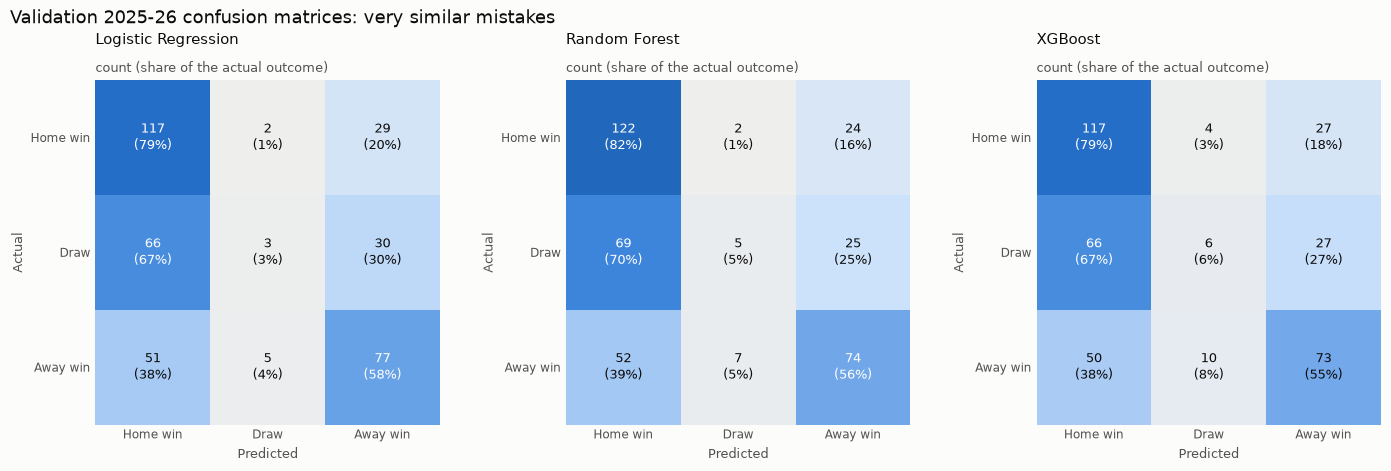

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), facecolor=SURFACE)
for ax, experiment in zip(axes, experiments.values()):
    matrix = experiment.validation[experiment.label]["confusion_matrix"]
    shares = matrix.div(matrix.sum(axis=1), axis=0)
    ax.imshow(shares.values, cmap=SEQ, vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{matrix.iloc[i, j]}\n({shares.iloc[i, j]:.0%})", ha="center", va="center",
                    fontsize=9, color="#ffffff" if shares.iloc[i, j] > 0.55 else INK)
    labels = [OUTCOME_NAMES[o] for o in OUTCOMES]
    ax.set_xticks(range(3), labels, fontsize=8.5, color=INK_2)
    ax.set_yticks(range(3), labels, fontsize=8.5, color=INK_2)
    ax.set_xlabel("Predicted", color=INK_2, fontsize=9)
    ax.set_ylabel("Actual", color=INK_2, fontsize=9)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    set_title(ax, experiment.label, "count (share of the actual outcome)", size=11)
fig.suptitle("Validation 2025-26 confusion matrices: very similar mistakes", x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(w_pad=3)
save_figure(fig, "20_tree_confusion_matrices.png")
plt.show()

**Interpretation**

- All three models beat the always-home-win baseline by a **similar, large margin** on both
  seasons.
- **On log loss** (the quality of the probabilities, and the metric we tuned for), Logistic
  Regression is marginally best on validation. On test it ties with XGBoost, while Random Forest
  is slightly behind.
- **On accuracy**, Random Forest is marginally ahead on both seasons, and it predicts a few more
  draws correctly.
- These gaps are tiny. On the 380-match validation season, one percentage point of accuracy is
  fewer than 4 matches; on the 100-match test season it is a single match. **None of the
  differences between the three models is meaningful at this sample size.**
- The tree models still almost never predict a draw, so the draw problem from notebook 03 isn't
  a weakness of linear models. It comes from how uncertain draws are.

## 4. Do the models learn the same thing?

In [10]:
val = {e.label: e.validation_results for e in experiments.values()}
predicted = pd.DataFrame({label: table["predicted"] for label, table in val.items()})
all_agree = (predicted.nunique(axis=1) == 1).mean()

probs_home = pd.DataFrame({label: table["prob_home_win"] for label, table in val.items()})
probs_draw = pd.DataFrame({label: table["prob_draw"] for label, table in val.items()})

print(f"All three models predict the same outcome in {all_agree:.1%} of validation matches")
display(probs_home.corr().round(3).style.format("{:.3f}").set_caption("Correlation of home-win probabilities"))
pd.DataFrame({
    "predicted draws": {label: (t["predicted"] == "D").mean() for label, t in val.items()},
    "lowest draw probability": probs_draw.min(),
    "highest draw probability": probs_draw.max(),
}).style.format("{:.1%}")

All three models predict the same outcome in 87.9% of validation matches


,Logistic Regression,Random Forest,XGBoost
Logistic Regression,1.000,0.970,0.980
Random Forest,0.970,1.000,0.981
XGBoost,0.980,0.981,1.000


,predicted draws,lowest draw probability,highest draw probability
Logistic Regression,2.6%,12.1%,39.7%
Random Forest,3.7%,7.0%,39.4%
XGBoost,5.3%,12.2%,47.0%


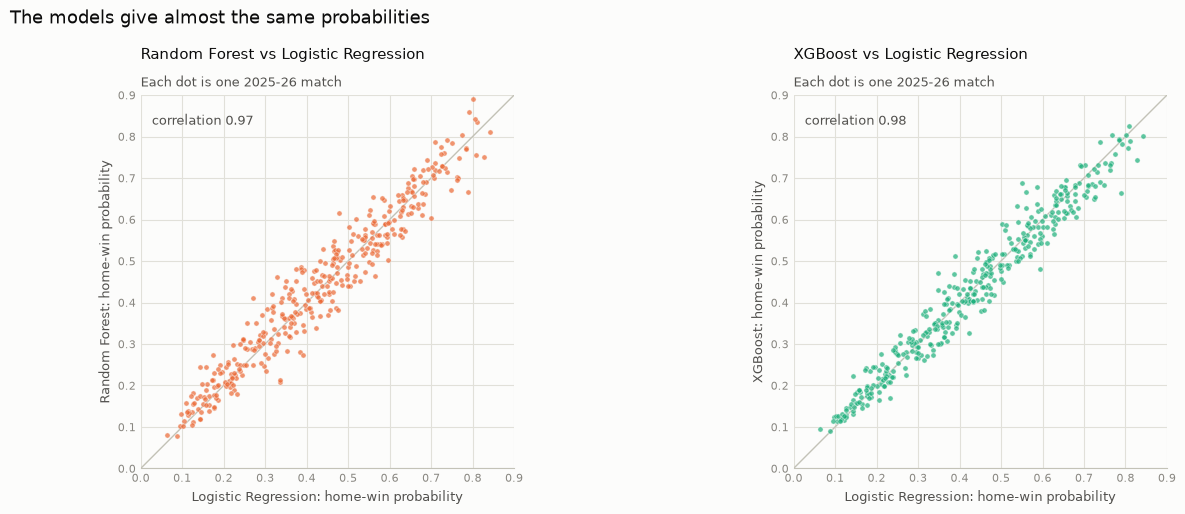

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), facecolor=SURFACE)
for ax, other in zip(axes, ["Random Forest", "XGBoost"]):
    ax.plot([0, 1], [0, 1], color=BASELINE, linewidth=1, zorder=1)
    ax.scatter(probs_home["Logistic Regression"], probs_home[other], s=14, color=MODEL_COLORS[other],
               alpha=0.7, edgecolors=SURFACE, linewidths=0.4, zorder=2)
    r = probs_home["Logistic Regression"].corr(probs_home[other])
    ax.text(0.03, 0.95, f"correlation {r:.2f}", transform=ax.transAxes, fontsize=9, color=INK_2, va="top")
    ax.set_xlim(0, 0.9)
    ax.set_ylim(0, 0.9)
    ax.set_aspect("equal")
    ax.set_xlabel("Logistic Regression: home-win probability", color=INK_2, fontsize=9)
    ax.set_ylabel(f"{other}: home-win probability", color=INK_2, fontsize=9)
    style_axes(ax, grid="both")
    set_title(ax, f"{other} vs Logistic Regression", "Each dot is one 2025-26 match", size=11)
fig.suptitle("The models give almost the same probabilities", x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(w_pad=4)
save_figure(fig, "21_model_agreement.png")
plt.show()

**Interpretation**

- The three models give the **same prediction for nearly 9 in 10 matches**, and their home-win
  probabilities are almost perfectly correlated.
- The extra flexibility of trees (non-linear effects, interactions between features) **does not
  find additional patterns** in these features. The relationship between team strength and the
  result is close to a smooth, monotonic one (notebook 02), which a linear model already
  captures.
- So the limit is the **information in the features, not the type of model**. Better
  predictions will most likely come from new information (for example bookmaker odds or
  player-level data) rather than a more complex algorithm.

## 5. Which features do the tree models rely on?

**Permutation importance** shuffles one feature at a time in the validation season and measures
how much the log loss gets worse. A feature the model doesn't use costs nothing when shuffled.
To keep it honest, the models are refitted on the training seasons only (1993-94 to 2024-25),
so the validation season is genuinely unseen.

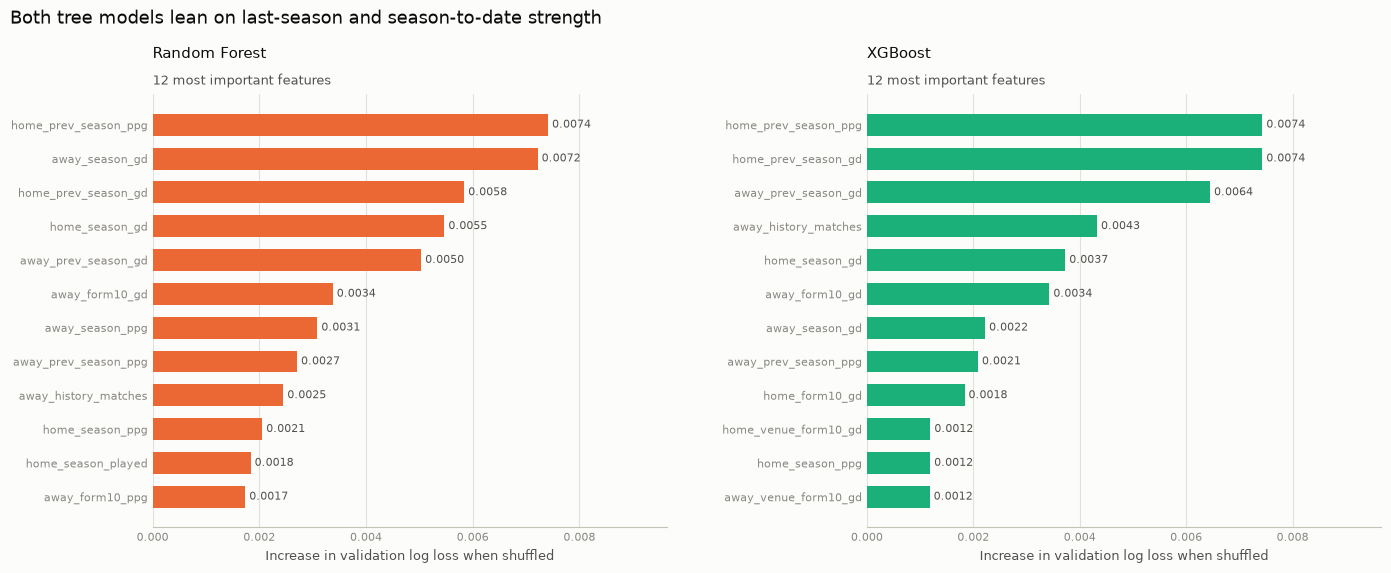

In [12]:
train, validation = chronological_split(features, TRAIN_LAST_SEASON, VALIDATION_SEASON)
importances = {}
for experiment in (rf, xgb):
    columns = experiment.feature_columns
    model = MODEL_SPECS[experiment.model_name].build(**experiment.params)
    model.fit(feature_matrix(train, columns), target(train))
    result = permutation_importance(
        model, feature_matrix(validation, columns), target(validation),
        scoring="neg_log_loss", n_repeats=10, random_state=42, n_jobs=1,
    )
    importances[experiment.label] = pd.Series(result.importances_mean, index=columns)
importance = pd.DataFrame(importances)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), facecolor=SURFACE)
for ax, label in zip(axes, importance.columns):
    top = importance[label].sort_values().tail(12)
    y = np.arange(len(top))
    ax.barh(y, top.values, color=MODEL_COLORS[label], height=0.65)
    for yi, v in zip(y, top.values):
        ax.text(v, yi, f" {v:.4f}", va="center", fontsize=8, color=INK_2)
    ax.set_yticks(y, top.index, fontsize=9, color=INK_2)
    ax.set_xlim(min(0, top.min() * 1.2), top.max() * 1.3)
    ax.set_xlabel("Increase in validation log loss when shuffled", color=INK_2, fontsize=9)
    style_axes(ax, grid="x")
    set_title(ax, label, "12 most important features", size=11)
fig.suptitle("Both tree models lean on last-season and season-to-date strength",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(w_pad=4)
save_figure(fig, "22_tree_feature_importance.png")
plt.show()

**Interpretation**

- Both models rely mostly on **last season's points and goal difference** and on this season's
  goal difference, for both teams. These are the same features that carry the largest
  Logistic Regression coefficients (notebook 03) and the strongest correlations (notebook 02).
- `away_history_matches` matters again: long-established clubs are stronger visitors.
- The importance values are small in absolute terms (thousandths of log loss), because the
  features overlap heavily. When one is shuffled, the model can still read similar information
  from its neighbours.

## Key findings

| Finding | Detail |
|---|---|
| All models beat the baseline | Validation log loss about 1.00 for each model, against 1.10 for the baseline |
| No model clearly wins | Gaps of 1–3 accuracy points and at most 0.013 log loss are well within the noise of 100–380 matches |
| Tree models need the right amount of constraint | Random Forest: depth 12, 10 matches per leaf. XGBoost: depth-2 trees, 250 rounds |
| The models agree | The same prediction for about 88% of matches; home-win probabilities correlate at about 0.97 |
| Same key features | Last-season and season-to-date strength dominate in every model |
| Draws are still rarely predicted | This is a property of the problem, not of the linear model |

## Next steps

- **Commit 8:** compare the history-based models in depth: calibration (are the probabilities
  right?), performance by season, statistical significance of the differences, and how close
  the models come to the bookmakers' odds.